1. What we're going to build (AI Assisted Notebook with ChatGPT)
2. Download an EEG dataset
3. Install the Python libraries

In [2]:
import mne
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from mne.datasets import eegbci
from mne.io import read_raw_edf, concatenate_raws

4. Load the EEG recordings

In [3]:
# Select participant and experimental runs
subject = 1
runs = [6, 10, 14]

# Download dataset
file_paths = eegbci.load_data(subject, runs)

# Read individual EDF files
raw_list = [
    read_raw_edf(file, preload=True)
    for file in file_paths
]

# Combine recordings
raw = concatenate_raws(raw_list)

# Standardize electrode names
eegbci.standardize(raw)

# Assign standard electrode positions
montage = mne.channels.make_standard_montage("standard_1005")
raw.set_montage(montage)

print(raw)

Using default location ~/mne_data for EEGBCI...
Creating C:\Users\erikt\mne_data


c:\Users\erikt\CodePractice\MNEDataAnalysis\eeg-analysis\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Attempting to create new mne-python configuration file:
C:\Users\erikt\.mne\mne-python.json
Could not read the C:\Users\erikt\.mne\mne-python.json json file during the writing. Assuming it is empty. Got: Expecting value: line 1 column 1 (char 0)
Download complete in 15s (7.4 MB)
Extracting EDF parameters from C:\Users\erikt\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R06.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Extracting EDF parameters from C:\Users\erikt\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R10.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
Extracting EDF parameters from C:\Users\erikt\mne_data\MNE-eegbci-data\files\eegmmidb\1.0.0\S001\S001R14.edf...
Setting channel info structure...
Creating raw.info structure...
Reading 0 ... 19999  =      0.000 ...   124.994 secs...
<RawEDF | S001R06.edf

C:\Users\erikt\AppData\Local\Temp\ipykernel_21816\82486247.py:21: FutureWarning: Montage name 'standard_1005' is deprecated and will be removed in MNE 1.14. Use 'colin27_1005' instead.
  montage = mne.channels.make_standard_montage("standard_1005")


5. Explore the dataset
A. Examine metadata
B. Visualize raw EEG signals
C. Visualize electrode positions

In [4]:
# Sampling frequency
print("Sampling frequency:", raw.info["sfreq"])

# Number of channels
print("Channels:", len(raw.ch_names))

# Channel names
print(raw.ch_names)

# Recording duration
duration = raw.times[-1]

print("Duration:", duration, "seconds")

# Data dimensions
data = raw.get_data()

print("Data shape:", data.shape)

Sampling frequency: 160.0
Channels: 64
['FC5', 'FC3', 'FC1', 'FCz', 'FC2', 'FC4', 'FC6', 'C5', 'C3', 'C1', 'Cz', 'C2', 'C4', 'C6', 'CP5', 'CP3', 'CP1', 'CPz', 'CP2', 'CP4', 'CP6', 'Fp1', 'Fpz', 'Fp2', 'AF7', 'AF3', 'AFz', 'AF4', 'AF8', 'F7', 'F5', 'F3', 'F1', 'Fz', 'F2', 'F4', 'F6', 'F8', 'FT7', 'FT8', 'T7', 'T8', 'T9', 'T10', 'TP7', 'TP8', 'P7', 'P5', 'P3', 'P1', 'Pz', 'P2', 'P4', 'P6', 'P8', 'PO7', 'PO3', 'POz', 'PO4', 'PO8', 'O1', 'Oz', 'O2', 'Iz']
Duration: 374.99375 seconds
Data shape: (64, 60000)


Using matplotlib as 2D backend.
For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


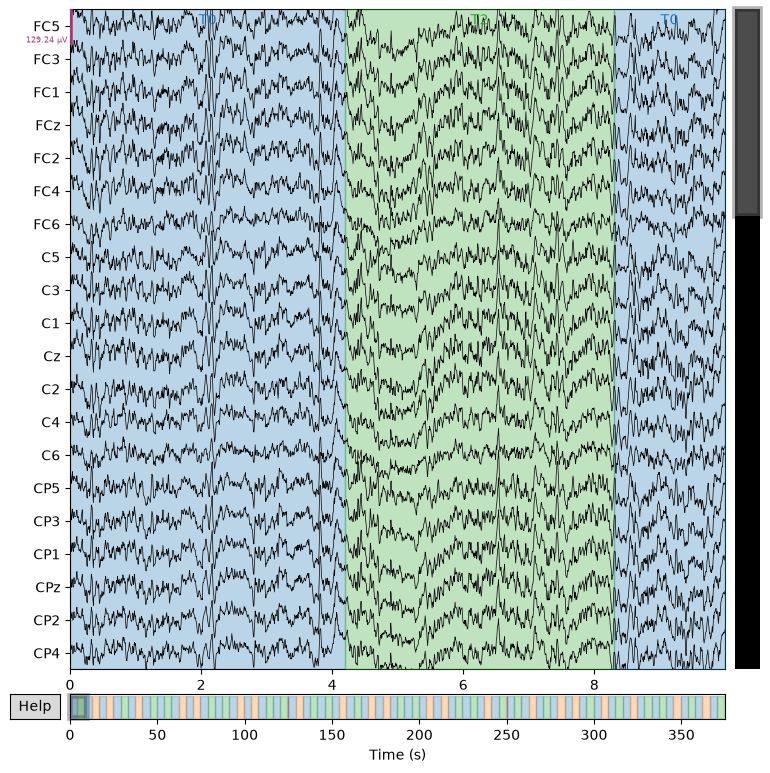

In [5]:
# Plot the raw EEG
raw.plot(
    duration=10,
    n_channels=20,
    scalings="auto"
)

plt.show()

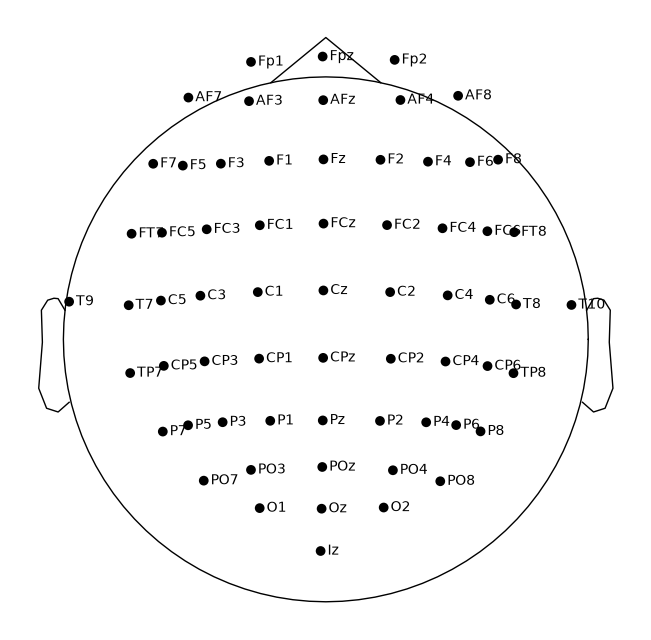

In [6]:
raw.plot_sensors(
    kind="topomap",
    show_names=True
)

plt.show()

6. Preprocess the EEG signals
A. Bandpass filtering
B. Compare filtered and unfiltered signals

In [7]:
# Filter EEG signals
raw_filtered = raw.copy()

raw_filtered.filter(
    l_freq=7,
    h_freq=30,
    fir_design="firwin",
    skip_by_annotation="edge"
)

Filtering raw data in 3 contiguous segments
Setting up band-pass filter from 7 - 30 Hz

FIR filter parameters
---------------------
Designing a one-pass, zero-phase, non-causal bandpass filter:
- Windowed time-domain design (firwin) method
- Hamming window with 0.0194 passband ripple and 53 dB stopband attenuation
- Lower passband edge: 7.00
- Lower transition bandwidth: 2.00 Hz (-6 dB cutoff frequency: 6.00 Hz)
- Upper passband edge: 30.00 Hz
- Upper transition bandwidth: 7.50 Hz (-6 dB cutoff frequency: 33.75 Hz)
- Filter length: 265 samples (1.656 s)



<RawEDF | S001R06.edf, 64 x 60000 (375.0 s), ~29.4 MiB, data loaded>

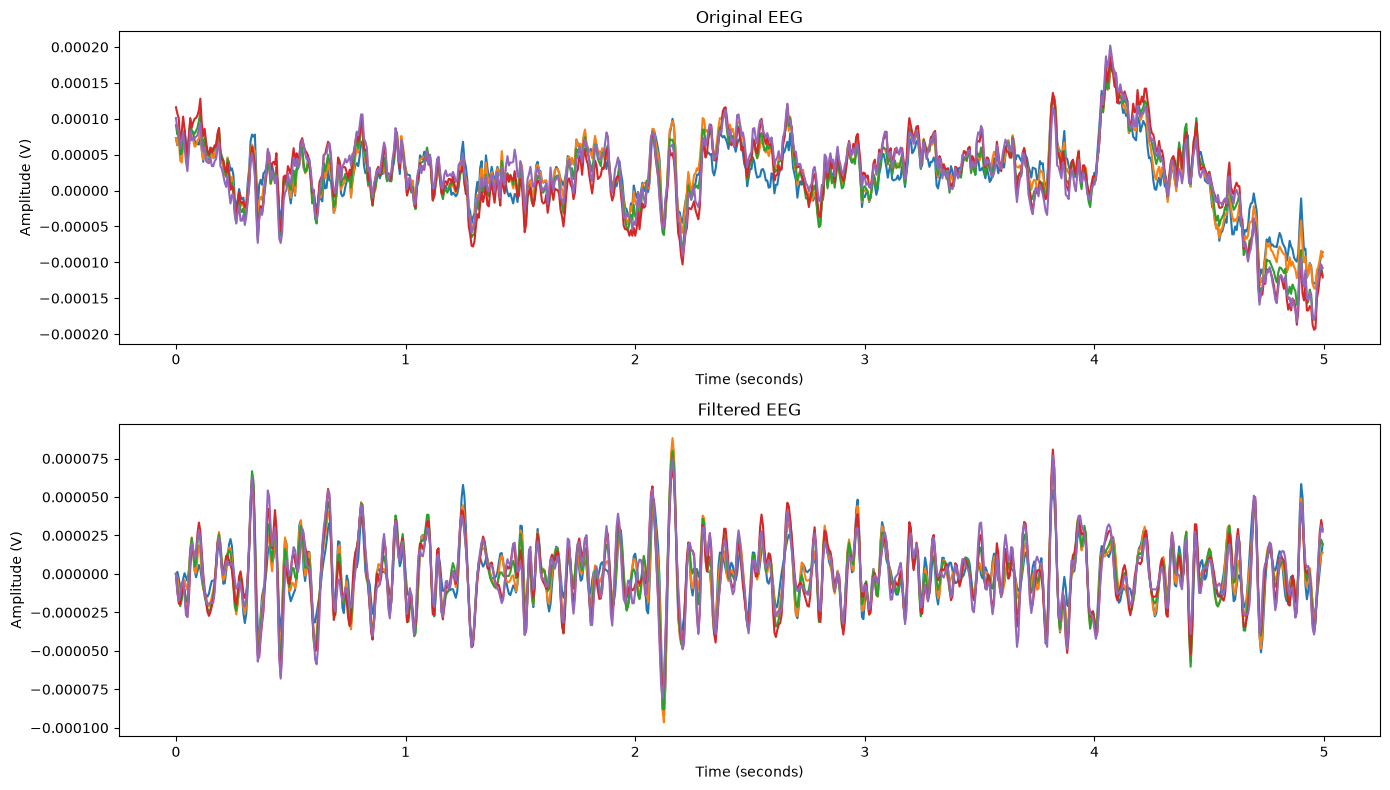

In [10]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8))

# Get first 5 channels
original_data = raw.get_data(picks="eeg")[:5, :]
filtered_data = raw_filtered.get_data(picks="eeg")[:5, :]

# Time axis (first 5 seconds)
sfreq = raw.info["sfreq"]
n_samples = int(5 * sfreq)

times = np.arange(n_samples) / sfreq

# Original
for i in range(5):
    axes[0].plot(times, original_data[i, :n_samples])

axes[0].set_title("Original EEG")
axes[0].set_xlabel("Time (seconds)")
axes[0].set_ylabel("Amplitude (V)")

# Filtered
for i in range(5):
    axes[1].plot(times, filtered_data[i, :n_samples])

axes[1].set_title("Filtered EEG")
axes[1].set_xlabel("Time (seconds)")
axes[1].set_ylabel("Amplitude (V)")

plt.tight_layout()
plt.show()

7. Extract experimental events and create epochs
A. Identify experimental events
B. Create epochs
C. Visualize individual epochs
D. Compare experimental conditions

In [11]:
raw_filtered.annotations.rename({
    "T1": "hands",
    "T2": "feet"
})
events, event_id = mne.events_from_annotations(
    raw_filtered
)

print(event_id)

Used Annotations descriptions: ['T0', 'feet', 'hands']
{'T0': 1, 'feet': 2, 'hands': 3}


In [12]:
epochs = mne.Epochs(
    raw_filtered,
    events,
    event_id={
        "hands": event_id["hands"],
        "feet": event_id["feet"]
    },
    tmin=-1,
    tmax=4,
    baseline=None,
    preload=True
)

print(epochs)

Not setting metadata
45 matching events found
No baseline correction applied
0 projection items activated
Using data from preloaded Raw for 45 events and 801 original time points ...
0 bad epochs dropped
<Epochs | 45 events (all good), -1 – 4 s (baseline off), ~17.7 MiB, data loaded,
 'hands': 21
 'feet': 24>


For automatic theme detection, "darkdetect" has to be installed! You can install it with `pip install darkdetect`


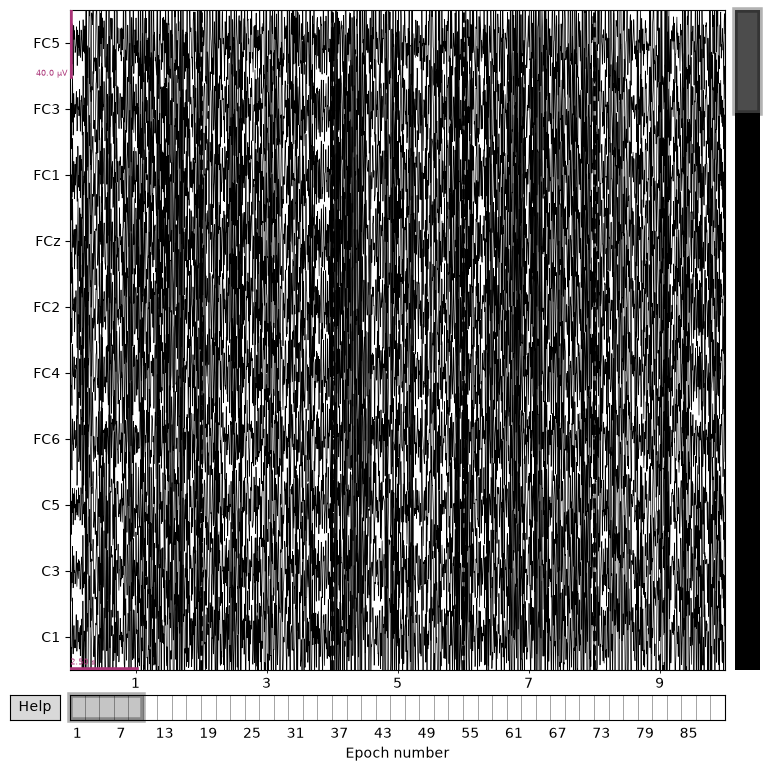

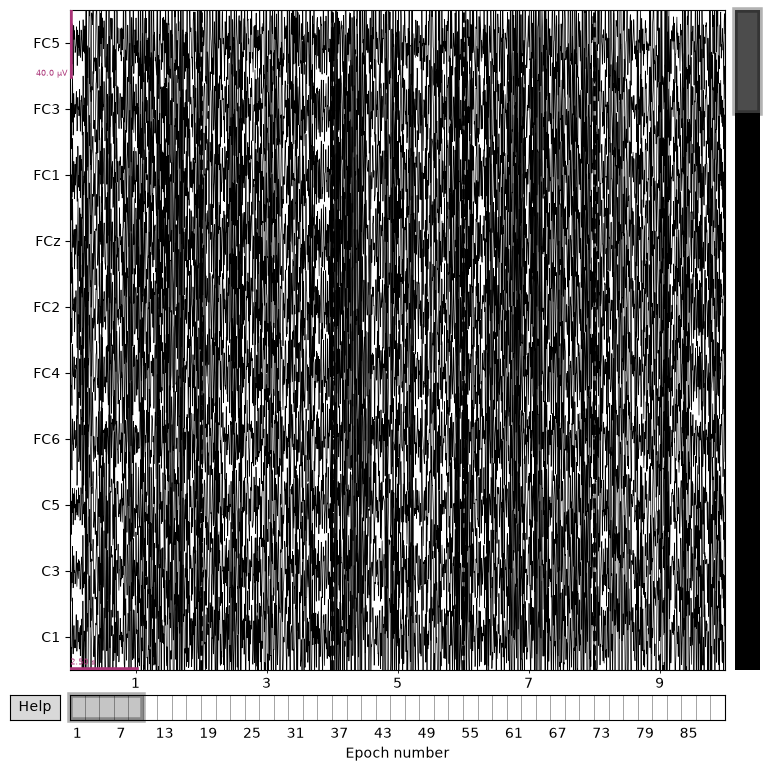

In [14]:
epochs.plot(
    n_epochs=5,
    n_channels=10
)

In [15]:
hands = epochs["hands"]
feet = epochs["feet"]

print("Hand trials:", len(hands))
print("Foot trials:", len(feet))

Hand trials: 21
Foot trials: 24


8. Frequency analysis and EEG visualizations
A. Power Spectral Density (PSD)
B. Topographic maps
C. Time-frequency analysis

Effective window size : 5.006 (s)
Plotting power spectral density (dB=True).
Averaging across epochs before plotting...


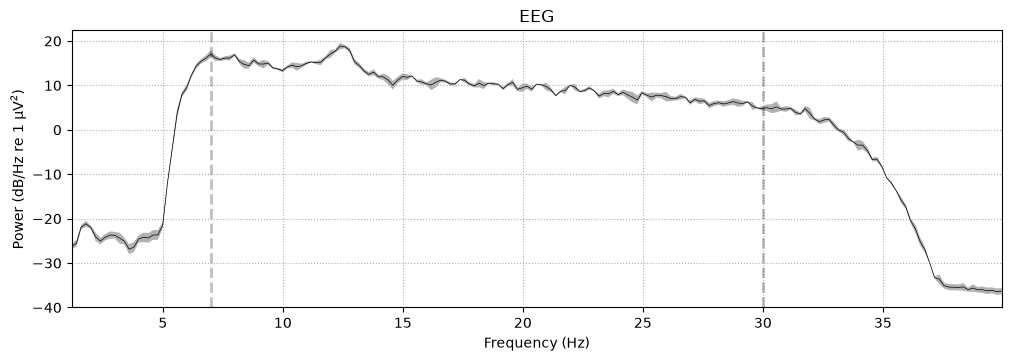

In [16]:
# Calculate power spectral density
spectrum = epochs.compute_psd(
    method="welch",
    fmin=1,
    fmax=40
)

# Visualize
spectrum.plot(
    average=True,
    picks=["C3", "C4"]
)

plt.show()

## A. Power Spectral Density (PSD)

Power Spectral Density (PSD) measures how the power of an EEG signal is distributed across different frequencies. This allows us to identify which frequency bands contain the most neural activity.

For this analysis, particular attention is given to the Mu (8–13 Hz) and Beta (13–30 Hz) frequency bands, which are associated with sensorimotor activity.

Comparing PSD between hand and feet motor imagery can help identify differences in brain activity patterns and determine whether frequency-based features can distinguish between the two tasks.

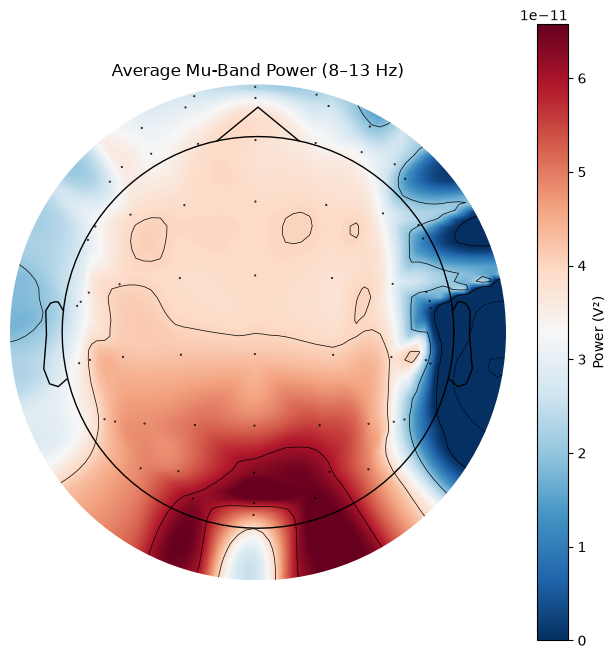

In [20]:
# Get electrode positions
positions = eeg_info.get_montage().get_positions()["ch_pos"]

# Match coordinates to channel order
coords = np.array([
    positions[ch]
    for ch in eeg_info.ch_names
])

# Keep only X and Y coordinates
coords = coords[:, :2]

# Plot
fig, ax = plt.subplots(figsize=(8, 8))

im, _ = mne.viz.plot_topomap(
    mu_power,
    coords,
    axes=ax,
    cmap="RdBu_r",
    contours=6,
    show=False
)

plt.colorbar(im, ax=ax, label="Power (V²)")
ax.set_title("Average Mu-Band Power (8–13 Hz)")

plt.show()

## B. Topographic Maps

Topographic maps provide a spatial representation of EEG activity across the scalp. Each electrode's measured activity is represented by a color, allowing us to visualize how brain activity is distributed across different regions.

By examining Mu-band power across the scalp, we can identify areas that exhibit stronger or weaker activity during hand and feet motor imagery.

These visualizations help investigate whether different motor imagery tasks produce distinguishable spatial patterns of neural activity.

Applying baseline correction (mode: logratio)


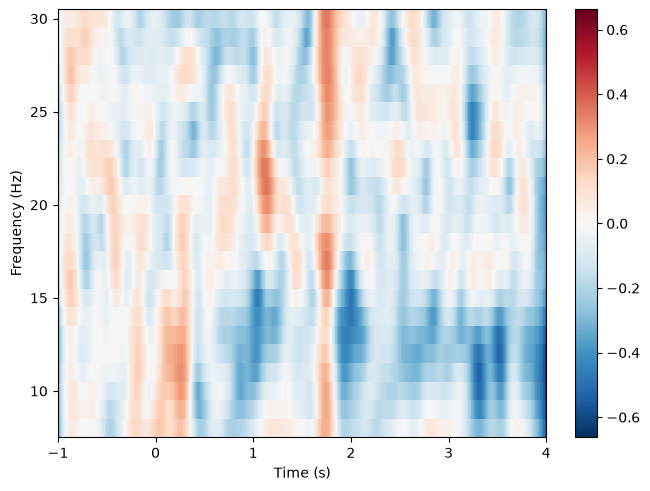

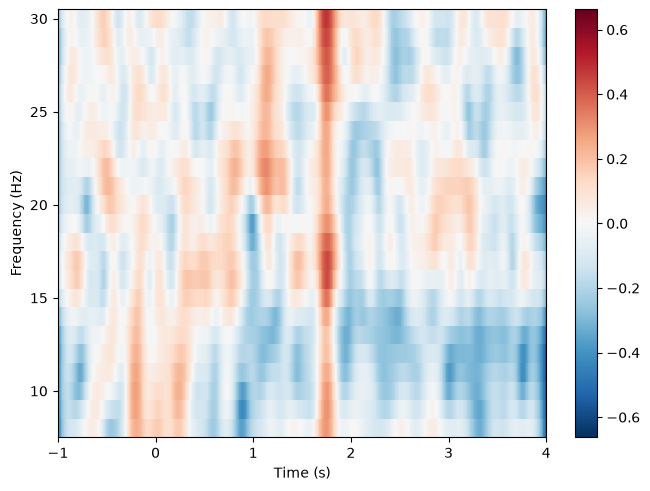

In [31]:
# Frequencies to investigate
freqs = np.arange(8, 31, 1)

# Number of wavelet cycles
n_cycles = freqs / 2

# Calculate time-frequency representation
tfr = hands.compute_tfr(
    method="morlet",
    freqs=freqs,
    n_cycles=n_cycles,
    average=True,
    return_itc=False
)

# Visualize selected channels
tfr.plot(
    picks=["C3", "C4"],
    baseline=(-1, 0),
    mode="logratio"
)

plt.show()

## C. Time-Frequency Analysis

Time-frequency analysis examines how the frequency content of EEG signals changes over time. Unlike PSD, which summarizes power across an entire signal or selected interval, time-frequency analysis allows us to observe when specific frequency bands increase or decrease in power.

This is particularly useful for investigating Event-Related Desynchronization (ERD) and Event-Related Synchronization (ERS), which describe decreases and increases in oscillatory power associated with motor imagery.

By examining changes in Mu and Beta activity before and after motor imagery events, we can better understand the temporal patterns of neural activity associated with hand and feet movement imagination.

9. Feature extraction
A. Frequency-band power
B. Statistical features
C. Create a Pandas DataFrame

In [22]:
# Focus on 1 to 4 seconds after the event
epochs_task = epochs.copy().crop(
    tmin=1,
    tmax=4
)

# Get EEG data
picks = mne.pick_types(
    epochs_task.info,
    eeg=True,
    exclude="bads"
)

data = epochs_task.get_data(picks=picks)

print(data.shape)

sfreq = epochs_task.info["sfreq"]

psd, freqs = mne.time_frequency.psd_array_welch(
    data,
    sfreq=sfreq,
    fmin=7,
    fmax=30,
    n_fft=256,
    n_per_seg=256,
    n_overlap=128,
    verbose=False
)

bands = {
    "mu": (8, 13),
    "beta": (13, 30)
}

features = {}

for band, (low, high) in bands.items():

    mask = (freqs >= low) & (freqs <= high)

    power = np.trapezoid(
        psd[..., mask],
        freqs[mask],
        axis=-1
    )

    features[band] = power

(45, 64, 481)


In [23]:
from scipy.stats import skew, kurtosis

# Data dimensions:
# epochs x channels x time

statistical_features = {
    "mean": np.mean(data, axis=2),
    "std": np.std(data, axis=2),
    "variance": np.var(data, axis=2),
    "rms": np.sqrt(np.mean(data ** 2, axis=2)),
    "skewness": skew(data, axis=2),
    "kurtosis": kurtosis(data, axis=2)
}

In [24]:
channel_names = [
    epochs_task.ch_names[i]
    for i in picks
]

feature_columns = {}

# Frequency features
for band, values in features.items():

    for i, channel in enumerate(channel_names):

        feature_columns[
            f"{channel}_{band}"
        ] = values[:, i]


# Statistical features
for feature_name, values in statistical_features.items():

    for i, channel in enumerate(channel_names):

        feature_columns[
            f"{channel}_{feature_name}"
        ] = values[:, i]


df = pd.DataFrame(feature_columns)

print(df.head())
print(df.shape)

         FC5_mu        FC3_mu        FC1_mu        FCz_mu        FC2_mu  \
0  1.364774e-10  2.188396e-10  2.061482e-10  1.823663e-10  1.852074e-10   
1  1.171732e-10  9.476626e-11  1.003512e-10  1.002338e-10  8.438682e-11   
2  1.069960e-10  1.265595e-10  1.320532e-10  1.578446e-10  1.272334e-10   
3  1.564175e-10  2.359330e-10  2.060104e-10  1.935414e-10  2.179011e-10   
4  5.850981e-10  5.975508e-10  6.369177e-10  6.282180e-10  6.458747e-10   

         FC4_mu        FC6_mu         C5_mu         C3_mu         C1_mu  ...  \
0  1.496120e-10  6.980729e-11  1.644608e-10  2.257438e-10  1.997865e-10  ...   
1  7.136378e-11  4.577496e-11  1.013572e-10  9.848344e-11  9.781466e-11  ...   
2  1.092483e-10  7.581148e-11  1.176728e-10  1.198500e-10  1.273407e-10  ...   
3  2.097403e-10  1.283671e-10  1.992007e-10  2.555458e-10  1.979705e-10  ...   
4  5.381673e-10  4.801625e-10  5.689729e-10  5.535657e-10  6.475224e-10  ...   

   P8_kurtosis  PO7_kurtosis  PO3_kurtosis  POz_kurtosis  PO4_kurtos

10. Statistical analysis

In [25]:
from scipy.stats import ttest_ind

# Identify motor cortex channels
motor_channels = ["C3", "C4"]

motor_indices = [
    channel_names.index(ch)
    for ch in motor_channels
    if ch in channel_names
]

# Average mu power for each trial
mu_power = features["mu"][:, motor_indices].mean(axis=1)

# Get trial labels
labels = epochs_task.events[:, -1]

hands_id = event_id["hands"]
feet_id = event_id["feet"]

hands_power = mu_power[labels == hands_id]
feet_power = mu_power[labels == feet_id]

# Independent samples t-test
result = ttest_ind(
    hands_power,
    feet_power,
    equal_var=False
)

print("Hands mean:", hands_power.mean())
print("Feet mean:", feet_power.mean())
print("T-statistic:", result.statistic)
print("P-value:", result.pvalue)

Hands mean: 1.4585016503608304e-10
Feet mean: 1.6828988336716238e-10
T-statistic: -0.8263025192893457
P-value: 0.4152142316131005


A P-Value of 0.415 computed given the Hands mean and Feet mean Mu-Band Power does not show a significant statistical evidence for a difference in Mu Band power between hands and feet. For a relationship to be concluded P-Value must be under 0.05. Further analysis must be done.

11. Machine learning: Classify brain activity
A. Prepare the labels
B. Split training and testing data
C. Train a classification model
D. Evaluate the model


In [26]:
labels = epochs_task.events[:, -1]

y = (labels == feet_id).astype(int)

X = df

print("Features:", X.shape)
print("Labels:", y.shape)

Features: (45, 512)
Labels: (45,)


In [27]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [28]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = make_pipeline(
    StandardScaler(),
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced"
    )
)

model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](512,)","['FC5_mu','FC3_mu','FC1_mu',...,'Oz_kurtosis','O2_kurtosis','Iz_kurtosis']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,512
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True


Accuracy: 0.7777777777777778
              precision    recall  f1-score   support

       Hands       0.75      0.75      0.75         4
        Feet       0.80      0.80      0.80         5

    accuracy                           0.78         9
   macro avg       0.78      0.78      0.78         9
weighted avg       0.78      0.78      0.78         9



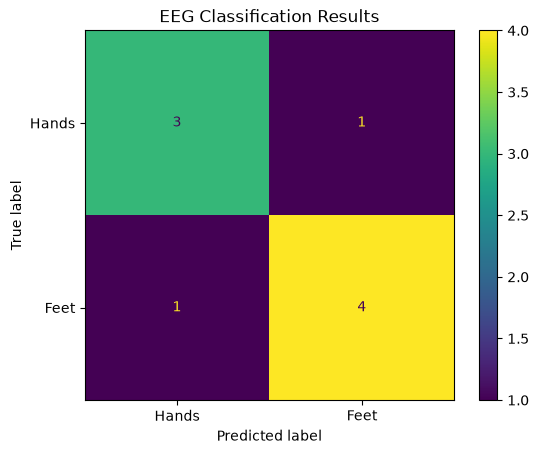

In [29]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

predictions = model.predict(X_test)

accuracy = accuracy_score(y_test, predictions)

print("Accuracy:", accuracy)

print(
    classification_report(
        y_test,
        predictions,
        target_names=["Hands", "Feet"]
    )
)

# Confusion matrix
cm = confusion_matrix(y_test, predictions)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Hands", "Feet"]
).plot()

plt.title("EEG Classification Results")
plt.show()

With a Accuracy of 78% the machine learning technique logical regression was able to predict between hand and feet in EEG recordings. However, a low sample size of 9 trials means there is great variation when put into use in a real world scenario. Each individual prediction has a significant impact on the overall accuracy, and the model's performance may vary considerably when applied to new EEG recordings or different participants.

To improve the model's reliability, future work should include a larger dataset, cross-validation, and testing on recordings from participants not used during training. Additionally, comparing Logistic Regression against other classification techniques, such as Support Vector Machines (SVM) and Random Forest, could help determine which approach performs best for this EEG classification task.